In [1]:
from pathlib import Path
from urllib.request import urlretrieve

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.base import BaseEstimator, RegressorMixin

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

URL = (
    "https://archive.ics.uci.edu/ml/machine-learning-databases/"
    "autos/imports-85.data"
)
DATA = Path("data")
FIGS = Path("figures")
DATA.mkdir(exist_ok=True)
FIGS.mkdir(exist_ok=True)
RAW = DATA / "imports-85.data"
if not RAW.exists():
    urlretrieve(URL, RAW)

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
plt.rcParams.update({
    "axes.edgecolor": "#52514e",
    "axes.labelcolor": "#0b0b0b",
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
    "axes.grid": True,
    "grid.color": "#e1e0d9",
    "axes.axisbelow": True,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 11,
})

print("pandas", pd.__version__, "seaborn", sns.__version__,
      "scikit-learn", sklearn.__version__)

pandas 3.1.1 seaborn 0.13.2 scikit-learn 1.9.1


In [2]:
headers = [
    "symboling", "normalized-losses", "make", "fuel-type",
    "aspiration", "num-of-doors", "body-style", "drive-wheels",
    "engine-location", "wheel-base", "length", "width", "height",
    "curb-weight", "engine-type", "num-of-cylinders", "engine-size",
    "fuel-system", "bore", "stroke", "compression-ratio",
    "horsepower", "peak-rpm", "city-mpg", "highway-mpg", "price",
]
df = pd.read_csv(RAW, names=headers)
df = df.replace("?", np.nan)
print("raw:", df.shape, "missing price:", int(df["price"].isnull().sum()))

df = df.dropna(subset=["price"]).reset_index(drop=True)
numeric = ["normalized-losses", "bore", "stroke", "horsepower", "peak-rpm", "price"]
df[numeric] = df[numeric].astype(float)
for col in numeric[:-1]:
    df[col] = df[col].fillna(df[col].mean())
df["num-of-doors"] = df["num-of-doors"].fillna(df["num-of-doors"].mode()[0])
print("clean:", df.shape, "NaN left:", int(df.isnull().sum().sum()))

raw: (205, 26) missing price: 4
clean: (201, 26) NaN left: 0


In [3]:
Y = df["price"]
x_train_idx, x_test_idx = train_test_split(df.index, test_size=0.2, random_state=1)
CV = KFold(n_splits=5, shuffle=True, random_state=1)
print("train:", len(x_train_idx), " test:", len(x_test_idx))


def evaluate(name, model, X):
    model.fit(X, Y)
    yhat = model.predict(X)
    r2_in = r2_score(Y, yhat)
    mse_in = mean_squared_error(Y, yhat)
    model.fit(X.loc[x_train_idx], Y.loc[x_train_idx])
    yhat_test = model.predict(X.loc[x_test_idx])
    r2_test = r2_score(Y.loc[x_test_idx], yhat_test)
    mse_test = mean_squared_error(Y.loc[x_test_idx], yhat_test)
    cv = cross_val_score(model, X, Y, cv=CV, scoring="r2").mean()
    model.fit(X, Y)
    return {"model": name, "R2_in": round(r2_in, 4), "MSE_in": f"{mse_in:.4e}",
            "R2_test": round(r2_test, 4), "MSE_test": f"{mse_test:.4e}",
            "R2_cv5": round(cv, 4)}

train: 160  test: 41


In [4]:
lm = LinearRegression()
X = df[["engine-size"]]
lm.fit(X, Y)
Yhat = lm.predict(X)
print("intercept a =", lm.intercept_)
print("slope b     =", lm.coef_[0])
print(f"price = {lm.intercept_:.2f} + {lm.coef_[0]:.4f} * engine-size")
print("Yhat[0:5]   =", Yhat[0:5].round(2))
print("R^2         =", lm.score(X, Y))
print("MSE         =", mean_squared_error(Y, Yhat))
print("RMSE        =", mean_squared_error(Y, Yhat) ** 0.5)

intercept a = -7963.338906281027
slope b     = 166.86001569141584
price = -7963.34 + 166.8600 * engine-size
Yhat[0:5]   = [13728.46 13728.46 17399.38 10224.4  14729.62]
R^2         = 0.7609686443622008
MSE         = 15021126.02517414
RMSE        = 3875.7097447014967


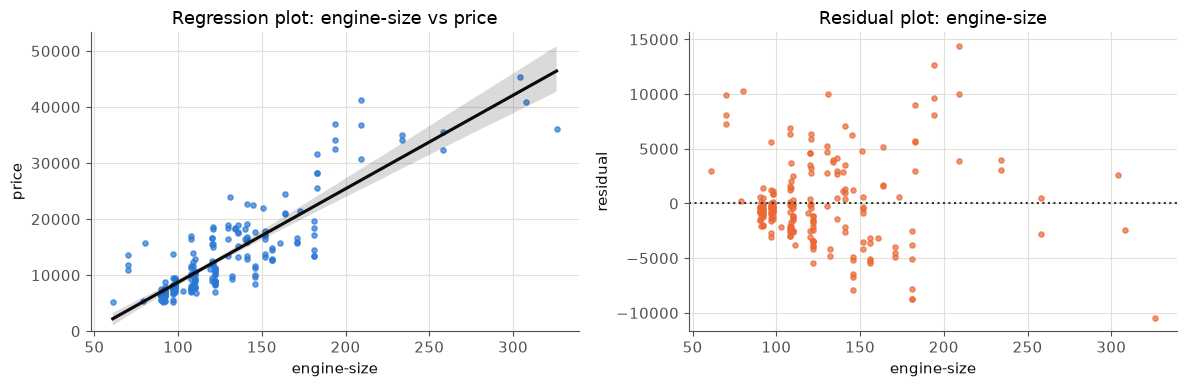

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.regplot(x="engine-size", y="price", data=df, ax=axes[0], color=PALETTE[0],
            scatter_kws={"s": 14, "alpha": 0.7}, line_kws={"color": "#0b0b0b"})
axes[0].set_ylim(0,)
axes[0].set_title("Regression plot: engine-size vs price")
sns.residplot(x=df["engine-size"], y=df["price"], ax=axes[1], color=PALETTE[1],
              scatter_kws={"s": 14, "alpha": 0.7})
axes[1].set_title("Residual plot: engine-size")
axes[1].set_ylabel("residual")
fig.tight_layout()
fig.savefig(FIGS / "task1_engine_size.png", dpi=200)
plt.show()

In [6]:
task1 = pd.DataFrame([
    evaluate("SLR engine-size", LinearRegression(), df[["engine-size"]]),
    evaluate("SLR highway-mpg", LinearRegression(), df[["highway-mpg"]]),
])
resid = Y - Yhat
print("residual mean =", round(resid.mean(), 6), " residual std =", round(resid.std(), 2))
print("share of |residual| > 5000:", round((resid.abs() > 5000).mean(), 4))
task1

residual mean = -0.0  residual std = 3885.39
share of |residual| > 5000: 0.1741


,model,R2_in,MSE_in,R2_test,MSE_test,R2_cv5
0,SLR engine-size,0.7610,1.5021e+07,0.6822,1.6843e+07,0.7491
1,SLR highway-mpg,0.4966,3.1635e+07,0.4447,2.9431e+07,0.4776


In [7]:
lm2 = LinearRegression()
Z = df[["normalized-losses", "highway-mpg"]]
lm2.fit(Z, Y)
Yhat2 = lm2.predict(Z)
print("intercept   =", lm2.intercept_)
print("coefficients =", {k: round(float(v), 4) for k, v in zip(Z.columns, lm2.coef_)})
print(f"price = {lm2.intercept_:.2f} + ({lm2.coef_[0]:.4f}) * normalized-losses"
      f" + ({lm2.coef_[1]:.4f}) * highway-mpg")
print("R^2 =", lm2.score(Z, Y))
print("MSE =", mean_squared_error(Y, Yhat2))
print(df[["normalized-losses", "highway-mpg", "price"]].corr().round(4))

intercept   = 38201.31327245727
coefficients = {'normalized-losses': 1.4979, 'highway-mpg': -820.4543}
price = 38201.31 + (1.4979) * normalized-losses + (-820.4543) * highway-mpg
R^2 = 0.4966263556974878
MSE = 31632832.975589428
                   normalized-losses  highway-mpg   price
normalized-losses             1.0000      -0.1819  0.1340
highway-mpg                  -0.1819       1.0000 -0.7047
price                         0.1340      -0.7047  1.0000


In [8]:
task2 = pd.DataFrame([
    evaluate("SLR highway-mpg", LinearRegression(), df[["highway-mpg"]]),
    evaluate("SLR normalized-losses", LinearRegression(), df[["normalized-losses"]]),
    evaluate("MLR normalized-losses + highway-mpg", LinearRegression(), Z),
])
task2

,model,R2_in,MSE_in,R2_test,MSE_test,R2_cv5
0,SLR highway-mpg,0.4966,3.1635e+07,0.4447,2.9431e+07,0.4776
1,SLR normalized-losses,0.0180,6.1713e+07,0.0225,5.1804e+07,-0.0002
2,MLR normalized-losses + highway-mpg,0.4966,3.1633e+07,0.4444,2.9443e+07,0.4718


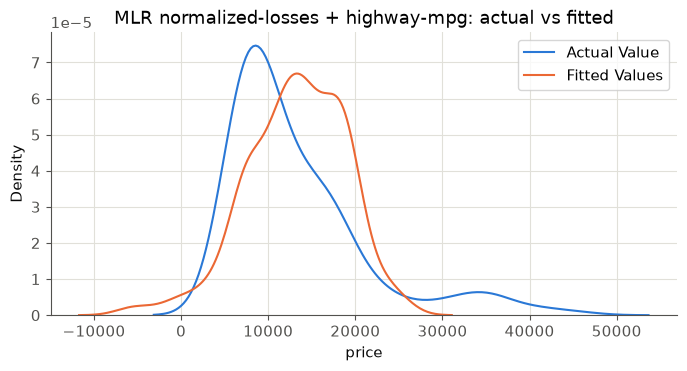

In [9]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.kdeplot(Y, color=PALETTE[0], label="Actual Value", ax=ax)
sns.kdeplot(Yhat2, color=PALETTE[1], label="Fitted Values", ax=ax)
ax.set_title("MLR normalized-losses + highway-mpg: actual vs fitted")
ax.set_xlabel("price")
ax.legend()
fig.tight_layout()
fig.savefig(FIGS / "task2_distribution.png", dpi=200)
plt.show()

In [10]:
x = df["highway-mpg"]
y = df["price"]
f11 = np.polyfit(x, y, 11)
p11 = np.poly1d(f11)
print("coefficients (x^11 ... x^0):")
print(np.array2string(f11, precision=4, max_line_width=110))
print("R^2 deg 11 =", r2_score(y, p11(x)))
print("MSE deg 11 =", mean_squared_error(y, p11(x)))
f3 = np.polyfit(x, y, 3)
p3 = np.poly1d(f3)
print(p3)
print("R^2 deg 3  =", r2_score(y, p3(x)))
print("MSE deg 3  =", mean_squared_error(y, p3(x)))

coefficients (x^11 ... x^0):
[-1.2426e-08  4.7218e-06 -8.0284e-04  8.0564e-02 -5.2974e+00  2.3947e+02 -7.5885e+03  1.6845e+05 -2.5653e+06
  2.5514e+07 -1.4911e+08  3.8793e+08]
R^2 deg 11 = 0.7023769092972938
MSE deg 11 = 18703127.6357796
        3         2
-1.557 x + 204.8 x - 8965 x + 1.379e+05
R^2 deg 3  = 0.6741946663906515
MSE deg 3  = 20474146.426361237


In [11]:
pipe11 = Pipeline([("scale", StandardScaler()),
                   ("polynomial", PolynomialFeatures(degree=11, include_bias=False)),
                   ("model", LinearRegression())])
pipe11.fit(df[["highway-mpg"]], y)
yhat_pipe = pipe11.predict(df[["highway-mpg"]])
print("Pipeline deg 11 R^2 =", r2_score(y, yhat_pipe))
print("Pipeline deg 11 MSE =", mean_squared_error(y, yhat_pipe))
print("max |polyfit - pipeline| =", np.abs(p11(x) - yhat_pipe).max().round(2))

Pipeline deg 11 R^2 = 0.6840347426020494
Pipeline deg 11 MSE = 19855779.750264157
max |polyfit - pipeline| = 4203.03


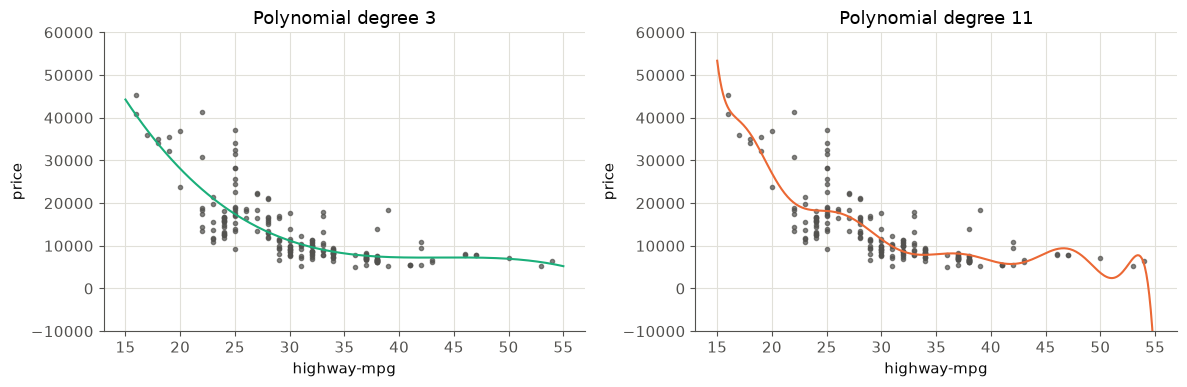

In [12]:
def plot_polly(ax, model, xs, ys, name, color):
    x_new = np.linspace(15, 55, 300)
    ax.plot(xs, ys, ".", color="#52514e", alpha=0.7)
    ax.plot(x_new, model(x_new), "-", color=color)
    ax.set_title(name)
    ax.set_xlabel("highway-mpg")
    ax.set_ylabel("price")
    ax.set_ylim(-10000, 60000)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
plot_polly(axes[0], p3, x, y, "Polynomial degree 3", PALETTE[2])
plot_polly(axes[1], p11, x, y, "Polynomial degree 11", PALETTE[1])
fig.tight_layout()
fig.savefig(FIGS / "task3_poly.png", dpi=200)
plt.show()

In [13]:
rows = []
for d in range(1, 12):
    pipe = Pipeline([("scale", StandardScaler()),
                     ("polynomial", PolynomialFeatures(degree=d, include_bias=False)),
                     ("model", LinearRegression())])
    res = evaluate(f"degree {d}", pipe, df[["highway-mpg"]])
    rows.append(res)
degree_table = pd.DataFrame(rows)
degree_table

,model,R2_in,MSE_in,R2_test,MSE_test,R2_cv5
0,degree 1,0.4966,3.1635e+07,0.4447,2.9431e+07,0.4776
1,degree 2,0.6518,2.1882e+07,0.5897,2.1745e+07,0.6317
2,degree 3,0.6742,2.0474e+07,0.6314,1.9535e+07,0.6597
3,degree 4,0.6748,2.0434e+07,0.6335,1.9420e+07,0.6591
4,degree 5,0.6788,2.0184e+07,0.6266,1.9789e+07,0.6610
5,degree 6,0.6820,1.9987e+07,0.6392,1.9122e+07,0.6666
6,degree 7,0.6823,1.9966e+07,0.6402,1.9067e+07,0.6660
7,degree 8,0.6875,1.9641e+07,0.6131,2.0505e+07,0.6587
8,degree 9,0.6957,1.9120e+07,0.6460,1.8760e+07,0.6625
9,degree 10,0.6958,1.9114e+07,0.6729,1.7332e+07,0.6630


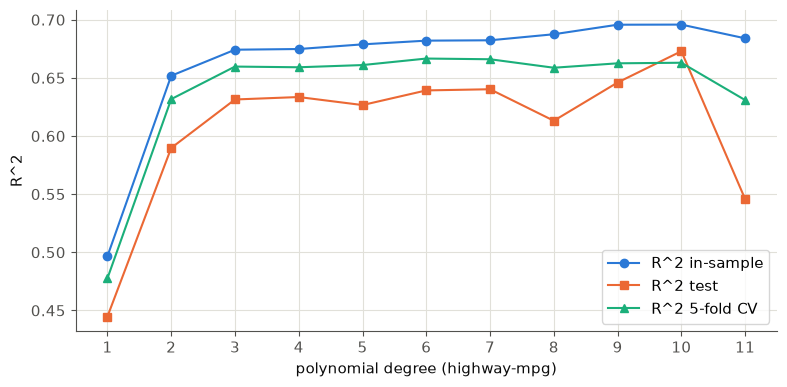

In [14]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(range(1, 12), degree_table["R2_in"], "o-", color=PALETTE[0], label="R^2 in-sample")
ax.plot(range(1, 12), degree_table["R2_test"], "s-", color=PALETTE[1], label="R^2 test")
ax.plot(range(1, 12), degree_table["R2_cv5"], "^-", color=PALETTE[2], label="R^2 5-fold CV")
ax.set_xlabel("polynomial degree (highway-mpg)")
ax.set_ylabel("R^2")
ax.set_xticks(range(1, 12))
ax.legend()
fig.tight_layout()
fig.savefig(FIGS / "task3_degree_r2.png", dpi=200)
plt.show()

In [15]:
features = ["horsepower", "curb-weight", "engine-size", "highway-mpg"]
print(df[features + ["price"]].corr()["price"].round(4))


class Poly1D(RegressorMixin, BaseEstimator):
    def __init__(self, degree=2):
        self.degree = degree

    def fit(self, X, y):
        self.poly_ = np.poly1d(np.polyfit(np.asarray(X)[:, 0], y, self.degree))
        return self

    def predict(self, X):
        return self.poly_(np.asarray(X)[:, 0])


models = [
    ("SLR horsepower", LinearRegression(), df[["horsepower"]]),
    ("MLR 4 features", LinearRegression(), df[features]),
    ("Poly deg 2 horsepower", Poly1D(2), df[["horsepower"]]),
    ("Poly deg 3 horsepower", Poly1D(3), df[["horsepower"]]),
    ("Pipeline deg 2, 4 features",
     Pipeline([("scale", StandardScaler()),
               ("polynomial", PolynomialFeatures(degree=2, include_bias=False)),
               ("model", LinearRegression())]), df[features]),
]
task4 = pd.DataFrame([evaluate(n, m, X) for n, m, X in models])
task4

horsepower     0.8097
curb-weight    0.8344
engine-size    0.8723
highway-mpg   -0.7047
price          1.0000
Name: price, dtype: float64


,model,R2_in,MSE_in,R2_test,MSE_test,R2_cv5
0,SLR horsepower,0.6556,2.1644e+07,0.5699,2.2792e+07,0.6436
1,MLR 4 features,0.8094,1.1977e+07,0.7429,1.3625e+07,0.7855
2,Poly deg 2 horsepower,0.6581,2.1485e+07,0.5759,2.2474e+07,0.6399
3,Poly deg 3 horsepower,0.6629,2.1182e+07,0.5742,2.2565e+07,0.6278
4,"Pipeline deg 2, 4 features",0.8463,9.6558e+06,0.7612,1.2658e+07,0.7976


intercept = -15824.04
coefficients = {'horsepower': 53.6104, 'curb-weight': 4.7089, 'engine-size': 81.4723, 'highway-mpg': 36.3964}


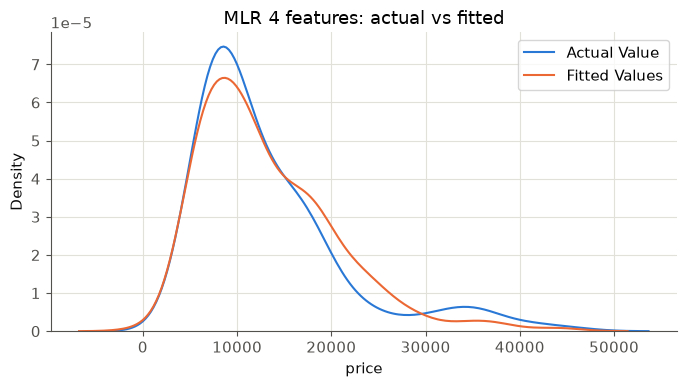

In [16]:
mlr = LinearRegression().fit(df[features], Y)
print("intercept =", round(mlr.intercept_, 2))
print("coefficients =", {k: round(float(v), 4) for k, v in zip(features, mlr.coef_)})
Y_hat_mlr = mlr.predict(df[features])
fig, ax = plt.subplots(figsize=(7, 4))
sns.kdeplot(Y, color=PALETTE[0], label="Actual Value", ax=ax)
sns.kdeplot(Y_hat_mlr, color=PALETTE[1], label="Fitted Values", ax=ax)
ax.set_title("MLR 4 features: actual vs fitted")
ax.set_xlabel("price")
ax.legend()
fig.tight_layout()
fig.savefig(FIGS / "task4_distribution.png", dpi=200)
plt.show()

In [17]:
new_cars = pd.DataFrame({
    "horsepower": [70, 110, 180],
    "curb-weight": [2000, 2600, 3300],
    "engine-size": [90, 130, 200],
    "highway-mpg": [38, 30, 22],
})
new_cars["price_pred_mlr"] = mlr.predict(new_cars[features]).round(0)
new_cars["price_pred_slr_engine"] = lm.predict(new_cars[["engine-size"]]).round(0)
new_cars

,horsepower,curb-weight,engine-size,highway-mpg,price_pred_mlr,price_pred_slr_engine
0,70,2000,90,38,6062.0,7054.0
1,110,2600,130,30,13999.0,13728.0
2,180,3300,200,22,26460.0,25409.0
